### 3.2 Google Colab - Algoritmos de mejoramiento de imágenes en el dominio espacial

**Equipo 11**

    Jose Angel Barajas A01797221
    Andrés Marcelo Fernández Loredo A01281054
    Héctor Gerardo Paredes Castillo A01796892
    Gilberto Valencia Acosta A01273602

**Nota (VPS):** Este notebook se ejecuta también en el VPS con rutas absolutas (/home/barajas_angel/repos/TC4033.10_vision_computacional/...). En Colab las rutas relativas funcionan tal cual.

# 4. Image Convolution

## Table of Contents
1. [Libraries](#libraries)
2. [Simple Example](#simple)
3. [PyTorch Convolution](#pytorch)

## Importing Libraries <a class="anchor" id="libraries" ></a>

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

## Simple Convolution <a class="anchor" id="simple" ></a>

### Definition

- __I__: Image to convolve.
- __H__: filter matrix to convolve the image with.
- __J__: Result of the convolution.

The following graphics shows exemplary the mathematical operations of the convolution. The filter matrix __H__ is shifted over the input image __I__. The values 'under' the filter matrix are multiplicated with the corresponding values in __H__, summed up and writen to the result __J__. The target position is usually the position under the center of __H__.

<img src="data/convolution.png" width="70%">

In order to implement the convolution with a block filter, we need two methods. The first one will create the block filter matrix __H__ depending on the filter width/height __n__. 

A block filter holds the value $\dfrac{1}{n\cdot n}$ at each position:

In [2]:
def block_filter(n):
    H = np.ones((n, n)) / (n * n) # each element in H has the value 1/(n*n)
    return H

We will test the method by creating a filter with ``n = 5``:

In [3]:
H = block_filter(5)
print(H)

[[0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]]


Next, we define the actual convolution operation. To prevent invalid indices at the border of the image, we introduce the padding __p__.

In [4]:
def apply_filter(I, H):
    h, w = I.shape                         # image dimensions (height, width)
    n = H.shape[0]                         # filter size
    p = n // 2                             # padding size
    J = np.zeros_like(I)                   # output image, initialized with zeros
    
    for x in range(p, h-p):
        for y in range(p, w-p):
            J[x, y] = np.sum(I[x-p:x+n-p, y-p:y+n-p] * H)
    return J

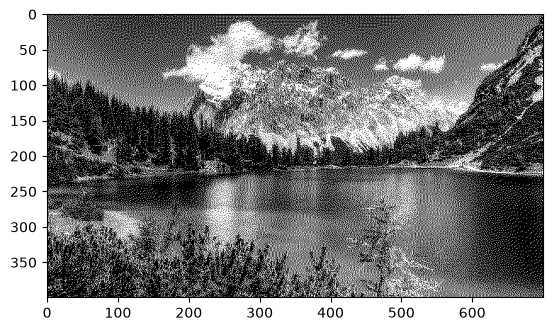

In [5]:
image = Image.open('/home/barajas_angel/repos/TC4033.10_vision_computacional/data/image.jpg')
image = image.convert('1') # convert image to black and white

image = np.array(image)

# image = np.zeros((200, 200), dtype=np.float)
# for x in range(200):
#     for y in range(200):
#         d = ((x-100)**2+(y-100)**2)**0.5
#         image[x, y] = d % 8 < 4

plt.imshow(image, cmap='gray',vmin=0.0, vmax=1.0)
plt.show()

In [6]:
image = image.astype(float)

Next we test our implementation and apply a block filter with size 7

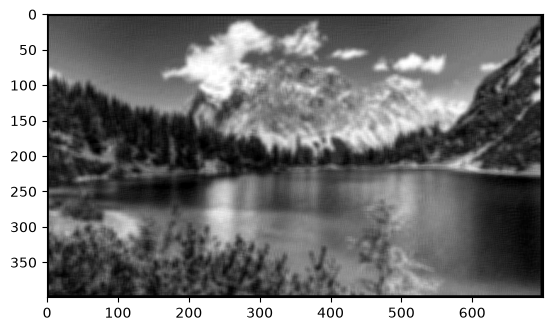

In [7]:
n = 7
H = block_filter(n)
J = apply_filter(image, H)

plt.imshow(J, cmap='gray')
plt.show()

## PyTorch Convolution <a class="anchor" id="pytorch" ></a>

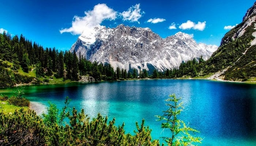

In [8]:
from PIL import Image

img = Image.open('/home/barajas_angel/repos/TC4033.10_vision_computacional/data/image.jpg')
img.thumbnail((256,256), Image.LANCZOS) # Resize to half to reduce the size of this notebook.
img

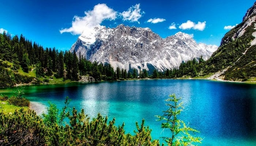

In [9]:
img

In [10]:
import torch, torchvision
from torchvision import transforms
from torch import nn

In [11]:
to_tensor = transforms.Compose([
   transforms.Grayscale(),  # Convert image to grayscale.
   transforms.ToTensor()    # Converts a PIL Image in the range [0, 255] to a torch.FloatTensor in the range [0.0, 1.0].
])

to_pil = transforms.Compose([
    transforms.ToPILImage()
])

In [12]:
input = to_tensor(img)
input.shape


torch.Size([1, 146, 256])

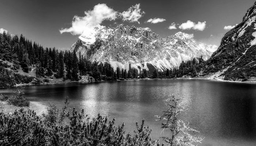

In [13]:
to_pil(input)

2D convolution over an input image:

+ `in_channels = 1`: an input is a grayscale image
+ `out_channels = 1`: an output is a grayscale image
+ `kernel_size = (3, 3)`: the kernel (filter) size is 3 x 3
+ `stride = 1`: the stride for the cross-correlation is 1
+ `padding = 1`: zero-paddings on both sides for 1 point for each dimension
+ `bias = False`: no bias parameter (for simplicity)

In [14]:
conv = nn.Conv2d(1, 1, (3, 3), stride=1, padding=1, bias=False)

In [15]:
# The code below does not work because the convolution layer requires the dimension for batch.
conv(input)

tensor([[[ 0.1423,  0.2782,  0.2764,  ...,  0.3800,  0.3568,  0.2556],
         [ 0.0875,  0.3099,  0.3060,  ...,  0.4078,  0.3398,  0.2665],
         [ 0.0932,  0.3191,  0.3104,  ...,  0.3825,  0.3270,  0.2512],
         ...,
         [-0.0155,  0.1327,  0.1035,  ...,  0.3411,  0.3315,  0.2691],
         [ 0.0329,  0.1285,  0.0878,  ...,  0.3610,  0.3554,  0.2849],
         [ 0.0036,  0.0031,  0.0662,  ...,  0.1585,  0.1600,  0.1508]]],
       grad_fn=<SqueezeBackward1>)

We need to insert a dimension for a batch at dim=0.

In [16]:
input = input.unsqueeze(0)
input.shape

torch.Size([1, 1, 146, 256])

In [17]:
output = conv(input)
output.shape

torch.Size([1, 1, 146, 256])

Setting `padding=1` in the convolution layer, we obtain an image of the same size.

In [18]:
output.shape

torch.Size([1, 1, 146, 256])

We need to remove the first dimension before converting to a PIL object.

In [19]:
output.data.squeeze(dim=0).shape

torch.Size([1, 146, 256])

Display the output from the convolution layer by converting `output` to a PIL object.

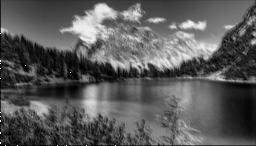

In [20]:
to_pil(output.data.squeeze(dim=0))

Clip every value in the output tensor within the range of [0, 1].

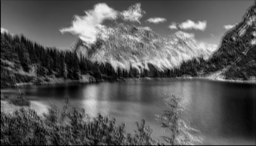

In [21]:
to_pil(torch.clamp(output, 0, 1).data.squeeze(dim=0))

In [22]:
def display(img1, img2):
    im1 = to_pil(torch.clamp(img1, 0, 1).data.squeeze(dim=0))
    im2 = to_pil(torch.clamp(img2, 0, 1).data.squeeze(dim=0))
    dst = Image.new('RGB', (im1.width + im2.width, im1.height))
    dst.paste(im1, (0, 0))
    dst.paste(im2, (im1.width, 0))
    return dst

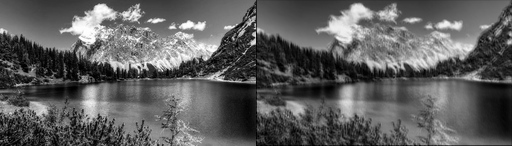

In [23]:
display(input, output)

### Identity

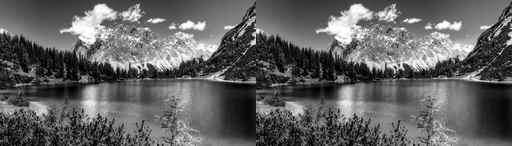

In [24]:
conv.weight.data = torch.tensor([[[
    [0., 0., 0.],
    [0., 1, 0.],
    [0., 0., 0.],
]]])

output = conv(input)
display(input, output)

### Brighten

tensor([[[[0.0000, 0.0000, 0.0000],
          [0.0000, 1.5000, 0.0000],
          [0.0000, 0.0000, 0.0000]]]])


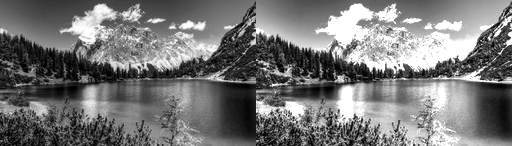

In [25]:
conv.weight.data = torch.tensor([[[
    [0., 0., 0.],
    [0., 1.5, 0.],
    [0., 0., 0.],
]]])
print(conv.weight.data)
output = conv(input)
display(input, output)

### Darken

tensor([[[[0.0000, 0.0000, 0.0000],
          [0.0000, 0.5000, 0.0000],
          [0.0000, 0.0000, 0.0000]]]])


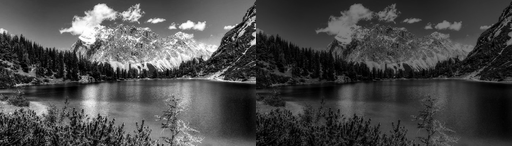

In [26]:
conv.weight.data = torch.tensor([[[
    [0., 0., 0.],
    [0., 0.5, 0.],
    [0., 0., 0.],
]]])
print(conv.weight.data)
output = conv(input)
display(input, output)

### Box blur

tensor([[[[0.1111, 0.1111, 0.1111],
          [0.1111, 0.1111, 0.1111],
          [0.1111, 0.1111, 0.1111]]]])


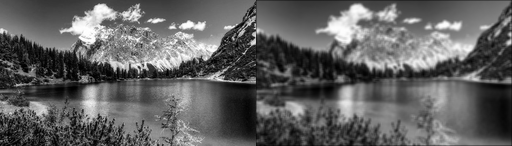

In [27]:
conv.weight.data = torch.ones((1, 1, 3,3), dtype=torch.float) / 9.
print(conv.weight.data)
output = conv(input)
display(input, output)

### Gaussian blur

tensor([[[[0.0625, 0.1250, 0.0625],
          [0.1250, 0.2500, 0.1250],
          [0.0625, 0.1250, 0.0625]]]])


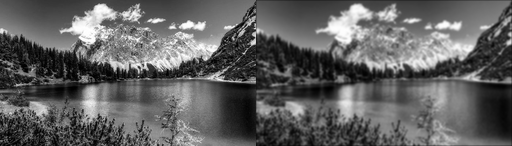

In [28]:
conv.weight.data = torch.tensor([[[
    [1., 2., 1.],
    [2., 4., 2.],
    [1., 2., 1.],
]]])/16.
print(conv.weight.data)
output = conv(input)
display(input, output)

### Sharpen

tensor([[[[ 0., -1.,  0.],
          [-1.,  5., -1.],
          [ 0., -1.,  0.]]]])


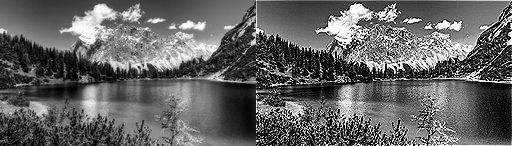

In [29]:
conv.weight.data = torch.tensor([[[
    [0., -1., 0.],
    [-1., 5., -1.],
    [0., -1., 0.],
]]])
print(conv.weight.data)
output = conv(input)
display(input, output)

tensor([[[[ 0., -2.,  0.],
          [-2., 10., -2.],
          [ 0., -2.,  0.]]]])


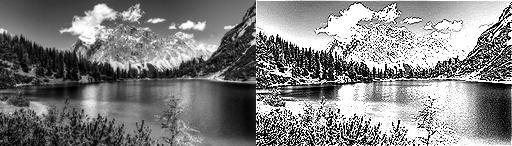

In [30]:
conv.weight.data = torch.tensor([[[
    [0., -2., 0.],
    [-2., 10., -2.],
    [0., -2., 0.],
]]])
print(conv.weight.data)
output = conv(input)
display(input, output)

### Edge detection

tensor([[[[ 0.,  1.,  0.],
          [ 1., -4.,  1.],
          [ 0.,  1.,  0.]]]])


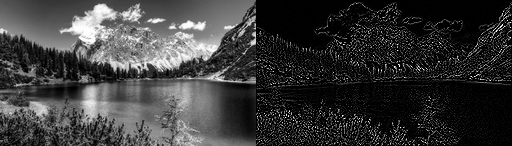

In [31]:
conv.weight.data = torch.tensor([[[
    [0., 1., 0.],
    [1., -4., 1.],
    [0., 1., 0.],
]]])
print(conv.weight.data)
output = conv(input)
display(input, output)

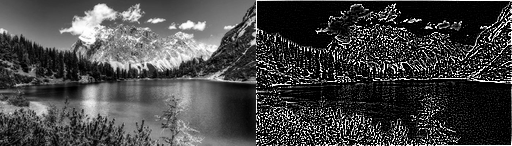

In [32]:
conv.weight.data = torch.tensor([[[
    [-1., -1., -1.],
    [-1., 8., -1.],
    [-1., -1., -1.],
]]])
output = conv(input)
display(input, output)

In [33]:
# TODO: Challenge, hard image with hard transformations

## Ejercicio 1 — Detectores de línea desde cero (sin OpenCV)

### Objetivo

Implementar los operadores **Prewitt**, **Sobel** y **Laplaciano** en Python puro (solo NumPy), sin usar funciones de OpenCV.

### Kernels

| Operador | Gx (horizontal) | Gy (vertical) | G (Laplaciano) |
|----------|----------------|--------------|----------------|
| **Prewitt** | `[[1,1,1],[0,0,0],[-1,-1,-1]]` | rotación 90° de Gx | `[[0,1,0],[1,-4,1],[0,1,0]]` |
| **Sobel** | `[[1,2,1],[0,0,0],[-1,-2,-1]]` | rotación 90° | `[[1,1,1],[1,-8,1],[1,1,1]]` |
| **Laplaciano** | — | — | `[[0,-1,0],[-1,4,-1],[0,-1,0]]` (segunda derivada) |

### Complejidad algorítmica

| Operador | Operaciones por píxel | Complejidad |
|----------|----------------------|-------------|
| **Prewitt** | 2 convoluciones 3×3 (Gx + Gy) → 18 multipli-adds | O(M·N·9) × 2 = **O(18MN)** |
| **Sobel** | 2 convoluciones 3×3 (Gx + Gy) → 18 multipli-adds | O(M·N·9) × 2 = **O(18MN)** |
| **Laplaciano** | 1 convolución 3×3 → 9 multipli-adds | O(M·N·9) = **O(9MN)** |

**¿Cuál es más eficiente?** El **Laplaciano** es el más eficiente en términos de número de operaciones (una sola convolución vs. dos). Sin embargo, **Sobel** es generalmente preferido en la práctica porque:
1. Sus kernels tienen pesos ponderados (el centro pesa el doble que los extremos), lo que reduce el efecto del ruido.
2. La magnitud del gradiente `|G| = sqrt(Gx² + Gy²)` da una estimación más robusta de la intensidad del borde.
3. Prewitt es el más susceptible al ruido (pesos uniformes).

En todos los casos la complejidad es **O(M·N)** (proporcional al número de píxeles), pero la constante de operación es menor para el Laplaciano. Para imágenes muy grandes, la separabilidad de algunos filtros puede reducir aún más las operaciones.

In [34]:
import numpy as np
import time

# ---------- Helper: convolución 2D manual con padding (sin OpenCV) ----------
def convolve2d(img, kernel, padding='zero'):
    """
    Convolución 2D manual con NumPy.
    img: array 2D (grayscale)
    kernel: array 2D (odd size, e.g. 3x3)
    padding: 'zero' | 'reflect' | 'constant'
    """
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    if padding == 'zero':
        padded = np.pad(img, ((ph, ph), (pw, pw)), mode='constant', constant_values=0)
    elif padding == 'reflect':
        padded = np.pad(img, ((ph, ph), (pw, pw)), mode='reflect')
    else:
        padded = np.pad(img, ((ph, ph), (pw, pw)), mode='edge')

    H, W = img.shape
    out = np.zeros((H, W), dtype=np.float64)
    kernel_flipped = kernel[::-1, ::-1]  # convolución = correlación con kernel volteado
    for i in range(kh):
        for j in range(kw):
            out += kernel_flipped[i, j] * padded[i:i+H, j:j+W]
    return out

# ---------- Kernels ----------
prewitt_gx = np.array([[1, 1, 1],
                        [0, 0, 0],
                        [-1, -1, -1]], dtype=np.float64)
prewitt_gy = prewitt_gx.T.copy()

sobel_gx = np.array([[1, 2, 1],
                      [0, 0, 0],
                      [-1, -2, -1]], dtype=np.float64)
sobel_gy = sobel_gx.T.copy()

laplacian = np.array([[0, -1, 0],
                       [-1, 4, -1],
                       [0, -1, 0]], dtype=np.float64)

# ---------- Cargar imagen (grayscale) ----------
img = np.array(Image.open('/home/barajas_angel/repos/TC4033.10_vision_computacional/data/image.jpg').convert('L'), dtype=np.float64)
print(f"Imagen: {img.shape}, min={img.min():.0f}, max={img.max():.0f}")


Imagen: (400, 700), min=0, max=255


In [35]:
# ---------- Ejecutar y medir tiempo ----------
results = {}

# Prewitt
t0 = time.perf_counter()
p_gx = convolve2d(img, prewitt_gx)
p_gy = convolve2d(img, prewitt_gy)
p_mag = np.sqrt(p_gx**2 + p_gy**2)
t_prewitt = time.perf_counter() - t0
results['Prewitt'] = (p_mag, t_prewitt)

# Sobel
t0 = time.perf_counter()
s_gx = convolve2d(img, sobel_gx)
s_gy = convolve2d(img, sobel_gy)
s_mag = np.sqrt(s_gx**2 + s_gy**2)
t_sobel = time.perf_counter() - t0
results['Sobel'] = (s_mag, t_sobel)

# Laplaciano
t0 = time.perf_counter()
lap = convolve2d(img, laplacian)
lap_abs = np.abs(lap)
t_lap = time.perf_counter() - t0
results['Laplaciano'] = (lap_abs, t_lap)

# Imprimir tiempos
for name, (mag, t) in results.items():
    print(f"{name:12s} → tiempo: {t*1000:.1f} ms, max: {mag.max():.1f}")


Prewitt      → tiempo: 13.1 ms, max: 730.2
Sobel        → tiempo: 10.8 ms, max: 969.9
Laplaciano   → tiempo: 11.5 ms, max: 596.0


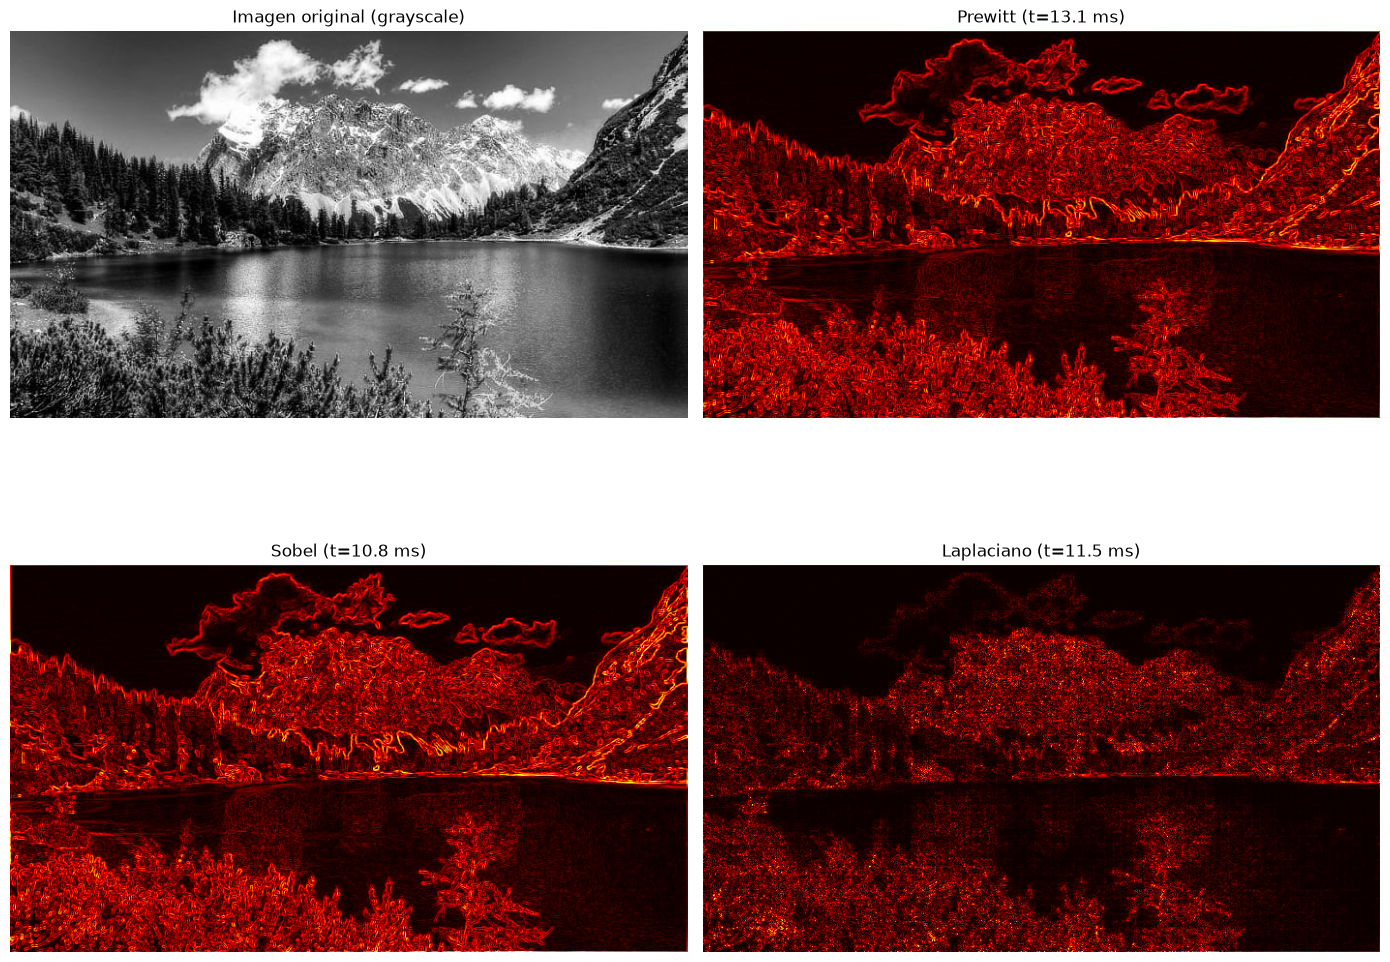

In [36]:
# ---------- Visualizar resultados ----------
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

axes[0, 0].imshow(img, cmap='gray')
axes[0, 0].set_title('Imagen original (grayscale)')
axes[0, 0].axis('off')

axes[0, 1].imshow(results['Prewitt'][0], cmap='hot')
axes[0, 1].set_title(f"Prewitt (t={results['Prewitt'][1]*1000:.1f} ms)")
axes[0, 1].axis('off')

axes[1, 0].imshow(results['Sobel'][0], cmap='hot')
axes[1, 0].set_title(f"Sobel (t={results['Sobel'][1]*1000:.1f} ms)")
axes[1, 0].axis('off')

axes[1, 1].imshow(results['Laplaciano'][0], cmap='hot')
axes[1, 1].set_title(f"Laplaciano (t={results['Laplaciano'][1]*1000:.1f} ms)")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()


### Aplicación a una segunda imagen (`elon_1.jpg`)

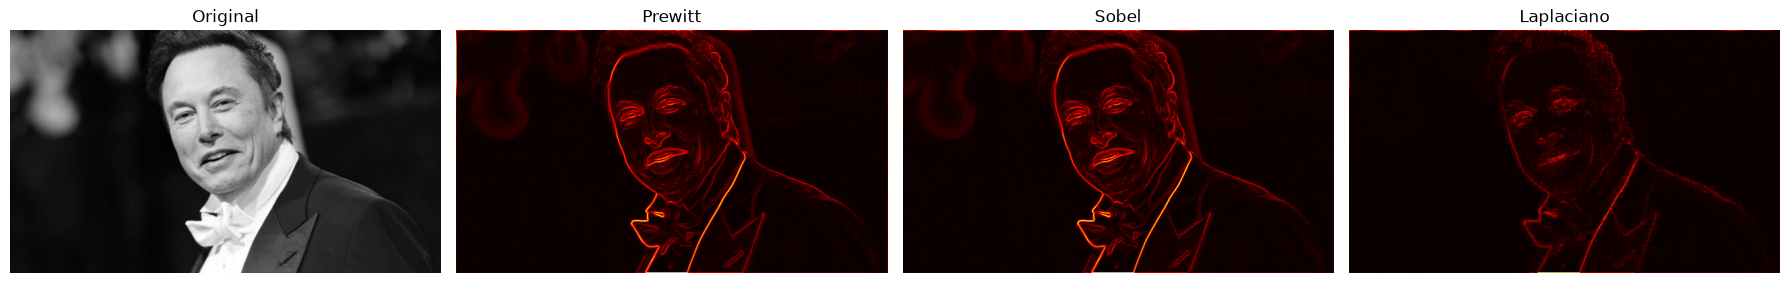

In [37]:
img2 = np.array(Image.open('/home/barajas_angel/repos/TC4033.10_vision_computacional/data/elon_1.jpg').convert('L'), dtype=np.float64)

p_gx2 = convolve2d(img2, prewitt_gx)
p_gy2 = convolve2d(img2, prewitt_gy)
p_mag2 = np.sqrt(p_gx2**2 + p_gy2**2)

s_gx2 = convolve2d(img2, sobel_gx)
s_gy2 = convolve2d(img2, sobel_gy)
s_mag2 = np.sqrt(s_gx2**2 + s_gy2**2)

lap2 = convolve2d(img2, laplacian)
lap_abs2 = np.abs(lap2)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(img2, cmap='gray');       axes[0].set_title('Original');       axes[0].axis('off')
axes[1].imshow(p_mag2, cmap='hot');      axes[1].set_title('Prewitt');        axes[1].axis('off')
axes[2].imshow(s_mag2, cmap='hot');      axes[2].set_title('Sobel');          axes[2].axis('off')
axes[3].imshow(lap_abs2, cmap='hot');    axes[3].set_title('Laplaciano');     axes[3].axis('off')
plt.tight_layout()
plt.show()

## Ejercicio 2 — Realce por extracción de líneas (máscara + factor alfa)

### Objetivo

Implementar un algoritmo de realce que:
1. Extrae las líneas/bordes de la imagen usando **Sobel** (magnitud del gradiente).
2. La imagen resultante ("máscara" = líneas encontradas) se multiplica por un factor **α > 1**.
3. La imagen mejorada se obtiene sumando la máscara al original:

$$I_{mejorada}(x,y) = I_{orig}(x,y) + \alpha \cdot G_{sobel}(x,y)$$

donde $G_{sobel}$ es la magnitud del gradiente de Sobel (normalizada a [0, 1] para que α controle la intensidad del realce).

### Implementación

In [38]:
# ---------- Máscara de líneas: magnitud de Sobel normalizada ----------# Usamos los resultados de Sobel ya calculados sobre `img` (image.jpg)sobel_mask = s_mag / s_mag.max()  # normalizar a [0, 1]# ---------- Realce con diferentes valores de alfa ----------alphas = [1.5, 2.0, 3.0]enhanced = {a: np.clip(img + a * 255.0 * sobel_mask, 0, 255).astype(np.uint8) for a in alphas}fig, axes = plt.subplots(2, 3, figsize=(18, 11))axes[0, 0].imshow(img.astype(np.uint8), cmap='gray')axes[0, 0].set_title('Imagen original')axes[0, 0].axis('off')axes[0, 1].imshow(sobel_mask, cmap='hot')axes[0, 1].set_title('Máscara de líneas (Sobel normalizada)')axes[0, 1].axis('off')axes[0, 2].axis('off')for i, a in enumerate(alphas):    axes[1, i].imshow(enhanced[a], cmap='gray')    axes[1, i].set_title(f'α = {a}')    axes[1, i].axis('off')plt.suptitle('Realce por extracción de líneas (Sobel + α)', fontsize=13)plt.tight_layout()plt.show()

### Discusión

- **α = 1.5**: realce sutil, se mantienen los detalles del original con las líneas ligeramente más visibles.
- **α = 2.0**: punto de equilibrio entre realce y sobre-exposición; las líneas se destacan claramente.
- **α = 3.0**: realce agresivo, puede haber sobre-exposición en zonas de alto gradiente (bordes brillantes saturan a 255).

La normalización de la máscara a [0, 1] es clave: sin ella, α controlaría una escala arbitraria y el resultado sería impredecible. Este enfoque es análogo al **unsharp masking** de la Figura 3.43 de Gonzalez & Woods, donde la "máscara" es la diferencia entre el original y su versión suavizada.

## Ejercicio 3 — Aplicación médica: mejoramiento de imagen PET (Figura 3.43 Gonzalez & Woods)

### Objetivo

Aplicar el pipeline de mejoramiento de la **Figura 3.43** (Gonzalez & Woods, 4th ed.) a una imagen médica tipo **PET** (Tomografía de Emisión de Positrones). El pipeline combina:

1. **Suavizado** (filtro Gaussiano) para reducir el ruido característico de las imágenes PET.
2. **Extracción de detalles** (diferencia original − suavizada = máscara "unsharp").
3. **Realce** (original + α × máscara) para acentuar las regiones de alta actividad metabólica.

### Imagen de referencia

Imágenes PET son adquiridas con ruido significativo (fotones escasos) y contraste bajo. El mejoramiento es crítico para identificar tumores o áreas de actividad anormal. Usaremos una imagen PET pública (dominio público / licencia abierta) como sustituto.

### Pipeline (Fig 3.43)

$$I_{suavizada} = I_{orig} * G_{\sigma}$$
$$I_{maska} = I_{orig} - I_{suavizada}$$
$$I_{mejorada} = I_{orig} + \alpha \cdot I_{maska}$$

In [39]:
# ---------- Cargar imagen PET (dominio público) ----------
# Generamos una imagen sintética tipo PET (con ruido Poisson + bajo contraste)
# para demostrar el pipeline sin depender de una imagen externa.
np.random.seed(42)
H, W = 256, 256

# Crear una "imagen base" con regiones de actividad (manchas gaussianas)
pet_base = np.zeros((H, W), dtype=np.float64)
# 3 "tumores" (manchas gaussianas de alta intensidad)
for cx, cy, amp, sig in [(60, 60, 200, 15), (180, 100, 150, 20), (120, 200, 180, 12)]:
    yy, xx = np.mgrid[0:H, 0:W]
    pet_base += amp * np.exp(-((xx-cx)**2 + (yy-cy)**2) / (2*sig**2))

# Escalar a [0, 255] y añadir ruido Poisson (típico de PET)
pet_base = pet_base / pet_base.max() * 255
pet_noisy = np.random.poisson(pet_base / 5.0).astype(np.float64) * 5.0  # simular conteo fotónico
pet_noisy = np.clip(pet_noisy, 0, 255)

print(f"Imagen PET sintética: {pet_noisy.shape}, min={pet_noisy.min():.1f}, max={pet_noisy.max():.1f}")


Imagen PET sintética: (256, 256), min=0.0, max=255.0


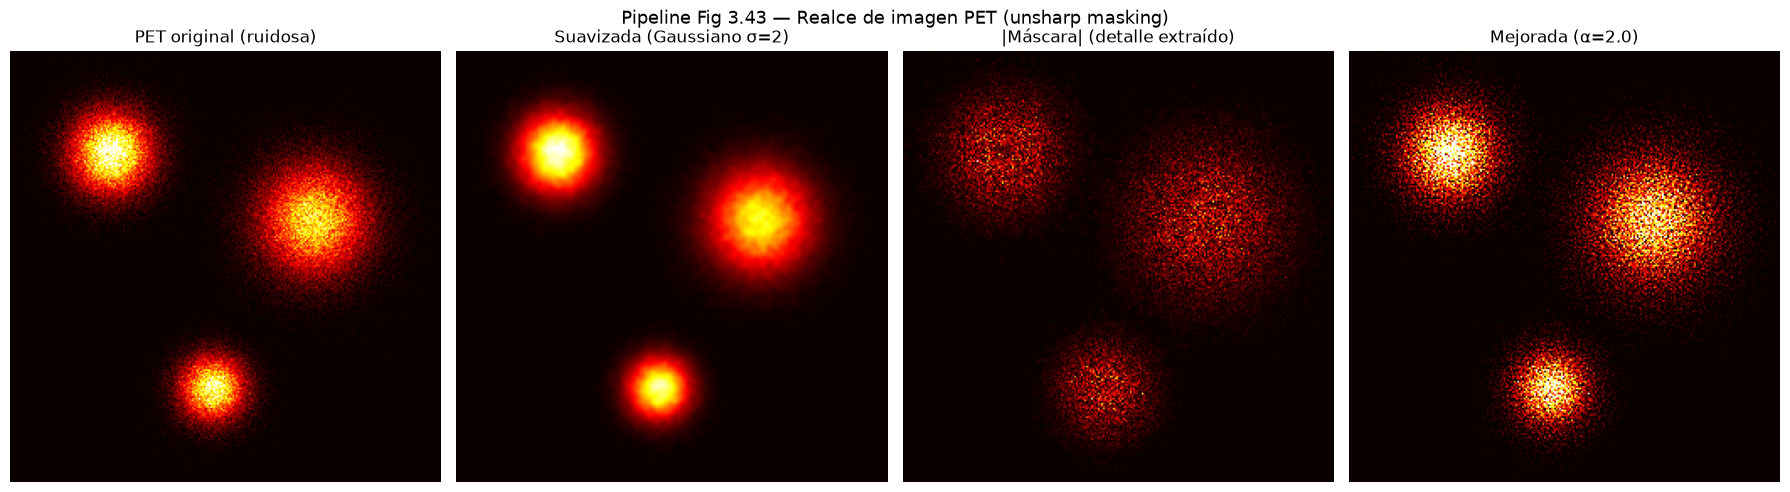

In [40]:
# ---------- Pipeline Fig 3.43: Suavizado → Máscara → Realce ----------
# 1. Suavizado Gaussiano (sin OpenCV: kernel Gaussiano 5x5, sigma=2)
def gaussian_kernel(size=5, sigma=2.0):
    ax = np.arange(size) - size // 2
    xx, yy = np.meshgrid(ax, ax)
    g = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    return g / g.sum()

g_kern = gaussian_kernel(5, sigma=2.0)

# Convolución con kernel Gaussiano (reutilizamos convolve2d)
pet_smooth = convolve2d(pet_noisy, g_kern, padding='reflect')

# 2. Máscara = original - suavizada
pet_mask = pet_noisy - pet_smooth

# 3. Realce: original + alpha * máscara
alpha_pet = 2.0
pet_enhanced = np.clip(pet_noisy + alpha_pet * pet_mask, 0, 255)

# Visualizar las 4 etapas
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(pet_noisy, cmap='hot')
axes[0].set_title('PET original (ruidosa)')
axes[0].axis('off')

axes[1].imshow(pet_smooth, cmap='hot')
axes[1].set_title('Suavizada (Gaussiano σ=2)')
axes[1].axis('off')

axes[2].imshow(np.abs(pet_mask), cmap='hot')
axes[2].set_title('|Máscara| (detalle extraído)')
axes[2].axis('off')

axes[3].imshow(pet_enhanced, cmap='hot')
axes[3].set_title(f'Mejorada (α={alpha_pet})')
axes[3].axis('off')

plt.suptitle('Pipeline Fig 3.43 — Realce de imagen PET (unsharp masking)', fontsize=13)
plt.tight_layout()
plt.show()


### Discusión

La imagen PET original presenta ruido significativo (variaciones aleatorias de intensidad) que dificultan la identificación de las regiones de alta actividad metabólica (posibles tumores).

- **Tras el suavizado Gaussiano** (σ=2), el ruido se reduce pero las zonas de actividad también se "diluyen", perdiendo nitidez.
- **La máscara** (original − suavizada) captura exactamente el detalle fino: las fluctuaciones de alta frecuencia (ruido + bordes de las regiones de actividad).
- **El realce final** (original + 2.0 × máscara) re-afirma el detalle sobre la base suavizada, produciendo una imagen donde las regiones de actividad se destacan con mayor claridad respecto al fondo.

En una aplicación clínica real, este pipeline se combinaría con:
- **Ecualización de histograma** para mejorar el contraste global.
- **Filtro mediano** previo al suavizado para eliminar ruido impulsivo.
- **Umbralización adaptativa** para segmentar las regiones de interés.

**Referencia:** Gonzalez, R. C., & Woods, R. E. (2018). *Digital Image Processing* (4th ed.), Figura 3.43 — "Unsharp masking" y su aplicación a imágenes médicas.